# Huấn luyện mô hình quyết định khớp bản thu

Dùng dấu vân tay phổ để xếp hạng ứng viên. Sau đó dùng hồi quy logistic để
quyết định có chấp nhận bài dẫn đầu hay từ chối. Notebook đánh giá mô hình này
cùng quy tắc gốc của app, theo từng mức nhiễu và theo bài trong/ngoài kho.

Trên tập kiểm tra cuối, hồi quy nhận đúng **100/108** đoạn trong kho, so với
**98/108** của quy tắc gốc. Cả hai từ chối đúng **54/54** đoạn ngoài kho.
Điểm cân bằng lần lượt là **96,3%** và **95,4%** trên tập này.

Bản public lưu mã, hệ số học được và số liệu tổng hợp. Để chạy lại, cần bộ dữ
liệu Loudio cục bộ gồm `tracks.csv`, `queries.csv` và các tệp FLAC tương ứng.

## 1. Chia tập theo bản thu

Tập huấn luyện dùng 20 bài từ nhóm hiệu chỉnh của thí nghiệm trước. Tập chọn
ngưỡng dùng 20 bài từ nhóm test đã từng xem. Tập kiểm tra cuối lấy 18 bài từ
nhóm trước đây chỉ lập chỉ mục, tức chưa được dùng làm truy vấn trong lần đánh
giá đó. Trong 18 bài này, 6 bài được loại khỏi chỉ mục. Chỉ mục cố định cho
cả ba tập gồm 84 bản thu. Với bài trong kho, đoạn dò được cắt từ cùng bản thu
tham chiếu. Các nhóm chỉ số đo nhận diện bản ghi, không đo nhận diện bản cover.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
from IPython.display import display
from scipy.optimize import minimize
from scipy.special import expit

ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "prototypes/match_model.py").is_file()
)
DATA = ROOT / "data/processed/loudio-hits"
if not (DATA / "tracks.csv").is_file() or not (DATA / "queries.csv").is_file():
    raise FileNotFoundError("Cần bộ dữ liệu Loudio cục bộ để chạy lại notebook.")
sys.path.insert(0, str(ROOT / "prototypes"))

import fingerprint as fp
from match_model import FEATURE_NAMES, match_features, match_score

tracks = pd.read_csv(DATA / "tracks.csv")
queries = pd.read_csv(DATA / "queries.csv")
assert len(tracks) == 100 and tracks["song_id"].is_unique
assert queries["clip_id"].is_unique

by_split = tracks.groupby("evaluation_split")["song_id"].apply(list)
rng = np.random.default_rng(20261127)
final_known, final_unknown = np.split(rng.permutation(by_split["reference_only"])[:18], [12])
sets = {
    "Huấn luyện": set(by_split["calibration_known"] + by_split["calibration_unknown"]),
    "Chọn ngưỡng": set(by_split["test_known"] + by_split["test_unknown"]),
    "Kiểm tra cuối": set(final_known) | set(final_unknown),
}
assert sum(map(len, sets.values())) == len(set.union(*sets.values()))
unknown = set(by_split["calibration_unknown"] + by_split["test_unknown"]) | set(final_unknown)
index_keys = [key for key in tracks["song_id"] if key not in unknown]
assert len(index_keys) == 84

split_table = pd.DataFrame([
    {"Tập": name, "Bài trong kho": len(ids - unknown), "Bài ngoài kho": len(ids & unknown),
     "Đoạn dò": int(queries["song_id"].isin(ids).sum())}
    for name, ids in sets.items()
])
display(split_table)

,Tập,Bài trong kho,Bài ngoài kho,Đoạn dò
0,Huấn luyện,15,5,180
1,Chọn ngưỡng,15,5,180
2,Kiểm tra cuối,12,6,162


## 2. Từ tín hiệu đến đặc trưng huấn luyện

Dùng quy trình DSP của app: mono 12 kHz → cửa sổ Hann và STFT → cặp đỉnh phổ →
phiếu theo độ lệch. Hồi quy logistic nhận ba số: log của phiếu dẫn đầu, chênh
lệch log giữa hai ứng viên dẫn đầu và log của số phiếu trên mỗi cặp đỉnh trong
đoạn dò. Nhãn dương nghĩa là bài dẫn đầu chính là đáp án. Đoạn ngoài kho hoặc
ứng viên dẫn đầu sai có nhãn âm.

In [2]:
def wave_file(relative_path, seconds):
    wave, rate = sf.read(DATA / relative_path, dtype="float32")
    assert rate == fp.SR and wave.shape == (seconds * fp.SR,)
    assert np.isfinite(wave).all()
    return wave

fp.RECORDINGS.update({key: ("", "", "") for key in index_keys})
reference_paths = tracks.set_index("song_id")["reference_file"]
index = fp.build_index({
    key: wave_file(reference_paths[key], fp.REFERENCE_SECONDS) for key in index_keys
})

def extract_rows(ids):
    rows = []
    for item in queries[queries["song_id"].isin(ids)].itertuples(index=False):
        result = fp.recognize(wave_file(item.clip_file, 5), index, index_keys)
        best, runner = result["candidates"][:2]
        rows.append({
            **dict(zip(FEATURE_NAMES, match_features(result), strict=True)),
            "condition": item.condition, "known": item.song_id not in unknown,
            "top_correct": best["key"] == item.song_id,
            "top_votes": best["votes"], "runner_votes": runner["votes"],
        })
    return pd.DataFrame(rows)

train = extract_rows(sets["Huấn luyện"])
valid = extract_rows(sets["Chọn ngưỡng"])
print(f"{len(index_keys)} bản tham chiếu · {len(train)} đoạn huấn luyện · {len(valid)} đoạn chọn ngưỡng")

84 bản tham chiếu · 180 đoạn huấn luyện · 180 đoạn chọn ngưỡng


## 3. Huấn luyện và chọn ngưỡng

Chuẩn hóa đặc trưng theo trung bình và độ lệch chuẩn của tập huấn luyện.
Hồi quy logistic giảm hàm mất mát log có phạt L2. Hai lớp được cân bằng theo
tần suất để việc từ chối sai không bị che bởi lớp đông hơn. Dùng tập chọn
ngưỡng để tối đa hóa trung bình tỷ lệ nhận đúng bài trong kho và tỷ lệ từ
chối đúng bài ngoài kho. Khi bằng điểm, ưu tiên từ chối đúng rồi chọn ngưỡng
cao hơn.

In [3]:
x = train[list(FEATURE_NAMES)].to_numpy()
y = train["top_correct"].to_numpy(dtype=float)
mean, scale = x.mean(axis=0), x.std(axis=0)
assert min(scale) > 0 and 0 < y.mean() < 1
design = np.column_stack([np.ones(len(x)), (x - mean) / scale])
weights = np.where(y == 1, 0.5 / y.mean(), 0.5 / (1 - y.mean()))
penalty = 0.02

def objective(params):
    logits = design @ params
    loss = np.mean(weights * (np.logaddexp(0, logits) - y * logits))
    gradient = design.T @ (weights * (expit(logits) - y)) / len(y)
    gradient[1:] += penalty * params[1:]
    return loss + penalty * (params[1:] @ params[1:]) / 2, gradient

fit = minimize(objective, np.zeros(design.shape[1]), jac=True, method="BFGS")
assert fit.success, fit.message
model = {
    "version": 1, "features": list(FEATURE_NAMES), "mean": mean.tolist(),
    "scale": scale.tolist(), "intercept": float(fit.x[0]), "coefficients": fit.x[1:].tolist(),
}

def summarize(frame, accepted):
    known = frame["known"]
    recognized = accepted & frame["top_correct"]
    correct = int((known & recognized).sum())
    rejected = int((~known & ~accepted).sum())
    known_n, unknown_n = int(known.sum()), int((~known).sum())
    return {
        "correct": correct, "known_n": known_n, "rejected": rejected, "unknown_n": unknown_n,
        "false_accept": unknown_n - rejected,
        "balanced": (correct / known_n + rejected / unknown_n) / 2,
    }

def scores(frame):
    return match_score(frame[list(FEATURE_NAMES)].to_numpy(), model)

valid_scores = scores(valid)
grid = pd.DataFrame([
    {"threshold": float(threshold),
     **summarize(valid, valid["top_votes"].gt(0) & (valid_scores >= threshold))}
    for threshold in np.linspace(0.05, 0.95, 19)
]).sort_values(["balanced", "rejected", "threshold"], ascending=False)
model["threshold"] = float(grid.iloc[0]["threshold"])
display(grid.head(5)[["threshold", "correct", "rejected", "balanced"]])

,threshold,correct,rejected,balanced
4,0.25,125,45,0.962963
5,0.30,122,45,0.951852
6,0.35,120,45,0.944444
8,0.45,119,45,0.940741
7,0.40,119,45,0.940741


## 4. So sánh trên tập kiểm tra cuối

Giữ nguyên mọi tham số sau khi chọn ngưỡng. So sánh với quy tắc yêu cầu 8 phiếu
và tỷ lệ 2 lần giữa hai bài dẫn đầu. Các biến thể nhiễu của cùng một đoạn
có liên hệ với nhau. Kết quả dựa trên 18 bản thu kiểm tra và nhiễu trắng mô phỏng.

In [4]:
final = extract_rows(sets["Kiểm tra cuối"])
assert len(final) == 162
conditions = {"clean": "Sạch", "snr10": "+10 dB", "snr-3": "−3 dB", "all": "Tổng"}
rows = []
for condition, label in conditions.items():
    part = final if condition == "all" else final[final["condition"].eq(condition)]
    baseline = part["top_votes"].ge(8) & part["top_votes"].ge(2 * part["runner_votes"])
    trained = part["top_votes"].gt(0) & (scores(part) >= model["threshold"])
    for method, accepted in (("Quy tắc gốc", baseline), ("Hồi quy logistic", trained)):
        rows.append({"Phương pháp": method, "Nhiễu": label, **summarize(part, accepted)})
metrics = pd.DataFrame(rows)
presentation = metrics.assign(
    Nhận_đúng=lambda x: x["correct"].astype(str) + "/" + x["known_n"].astype(str),
    Từ_chối_đúng=lambda x: x["rejected"].astype(str) + "/" + x["unknown_n"].astype(str),
    Cân_bằng=lambda x: x["balanced"].map(lambda v: f"{v:.1%}"),
)
display(presentation[["Phương pháp", "Nhiễu", "Nhận_đúng", "Từ_chối_đúng", "Cân_bằng"]].rename(
    columns={"Nhận_đúng": "Nhận đúng", "Từ_chối_đúng": "Từ chối đúng", "Cân_bằng": "Cân bằng"}
))

,Phương pháp,Nhiễu,Nhận đúng,Từ chối đúng,Cân bằng
0,Quy tắc gốc,Sạch,35/36,18/18,98.6%
1,Hồi quy logistic,Sạch,35/36,18/18,98.6%
2,Quy tắc gốc,+10 dB,35/36,18/18,98.6%
3,Hồi quy logistic,+10 dB,35/36,18/18,98.6%
4,Quy tắc gốc,−3 dB,28/36,18/18,88.9%
5,Hồi quy logistic,−3 dB,30/36,18/18,91.7%
6,Quy tắc gốc,Tổng,98/108,54/54,95.4%
7,Hồi quy logistic,Tổng,100/108,54/54,96.3%


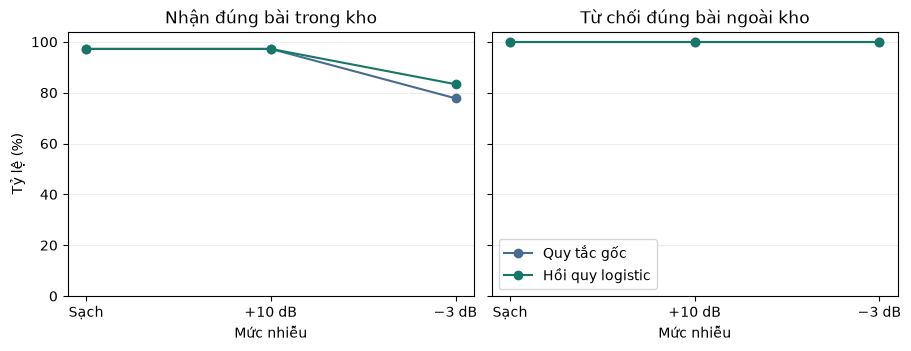

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), layout="constrained", sharey=True)
for ax, key, total, title in zip(
    axes, ("correct", "rejected"), ("known_n", "unknown_n"),
    ("Nhận đúng bài trong kho", "Từ chối đúng bài ngoài kho"),
    strict=True,
):
    for (method, group), color in zip(
        metrics[metrics["Nhiễu"].ne("Tổng")].groupby("Phương pháp", sort=False),
        ("#476b91", "#167766"), strict=True,
    ):
        ax.plot(group["Nhiễu"], 100 * group[key] / group[total], marker="o", label=method, color=color)
    ax.set(title=title, xlabel="Mức nhiễu", ylim=(0, 104))
    ax.grid(axis="y", alpha=0.22)
axes[0].set_ylabel("Tỷ lệ (%)")
axes[1].legend(loc="lower left")
plt.show()

## 5. Xuất mô hình

Tệp JSON chỉ chứa tham số chuẩn hóa, hệ số hồi quy và ngưỡng. Khi chọn chế độ
hồi quy trên Streamlit, app dùng các hệ số đó trên điểm đối sánh của kho công
khai. Kho công khai có 5 bản thu khác với kho 84 bản của thí nghiệm. Điểm
mô hình là điểm quyết định và không phải xác suất đã được kiểm định cho app
công khai, các độ dài khác 5 giây hoặc điều kiện ghi âm thực tế.

In [6]:
output = ROOT / "prototypes/match_model.json"
output.write_text(json.dumps(model, indent=2, allow_nan=False) + "\n", encoding="utf-8")
print(f"Đã xuất {output.relative_to(ROOT)} · ngưỡng {model['threshold']:.2f}")
for row in metrics[metrics["Nhiễu"].eq("Tổng")].to_dict(orient="records"):
    print(f"{row['Phương pháp']}: {row['correct']}/{row['known_n']} nhận đúng, "
          f"{row['rejected']}/{row['unknown_n']} từ chối đúng, cân bằng {row['balanced']:.1%}.")

Đã xuất prototypes/match_model.json · ngưỡng 0.25
Quy tắc gốc: 98/108 nhận đúng, 54/54 từ chối đúng, cân bằng 95.4%.
Hồi quy logistic: 100/108 nhận đúng, 54/54 từ chối đúng, cân bằng 96.3%.
